## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Anastacia Oliynyk

**Date:** 10/12/2026

In [73]:
# Your Phase 1 solution to the problem goes here.

In [74]:
#Q.1.1

import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

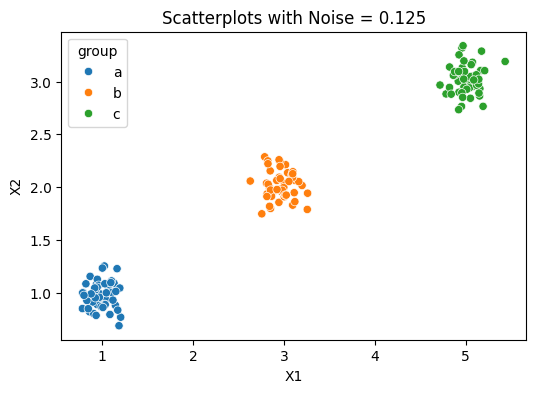

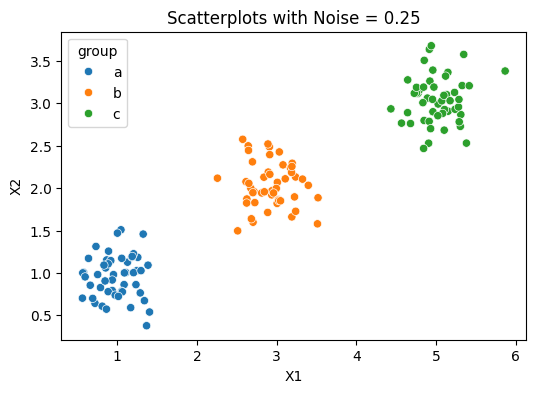

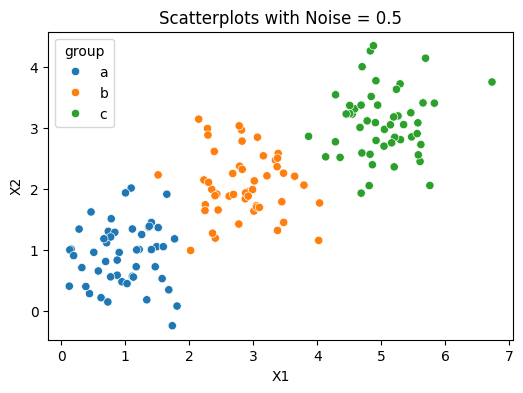

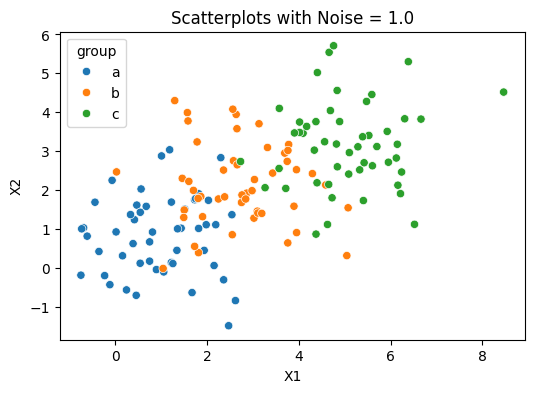

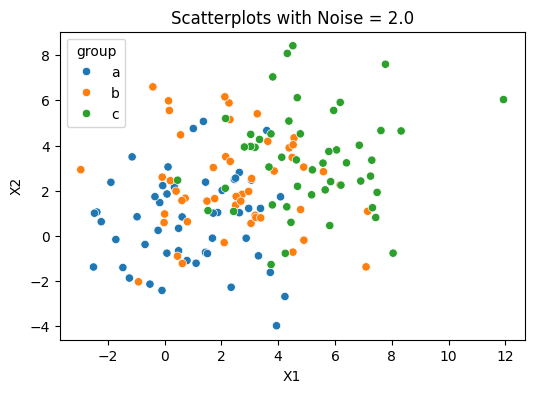

In [75]:
#Q.1.2

import matplotlib.pyplot as plt
import seaborn as sns

datasets = [df0_125, df0_25, df0_5, df1_0, df2_0]
noise_levels = [0.125, 0.25, 0.5, 1.0, 2.0]

for i in range(len(datasets)):
  plt.figure(figsize=(6,4))
  sns.scatterplot(data=datasets[i], x="x1", y="x2", hue="group")
  plt.title("Scatterplots with Noise = " + str(noise_levels[i]))
  plt.xlabel("X1")
  plt.ylabel("X2")
  plt.show()

As the noise increases from 0.125 to 2, the clusters spread out more. at lower noise levels, the three groups are closely concentrated around their centers. as the noise increases to .5 and 1, the points become more spread out and the clusters start to overlap. at 2 there is much more overlap between the groups, making it difficult to visually separate them. increasing noise makes clusters less defined and harder to identify

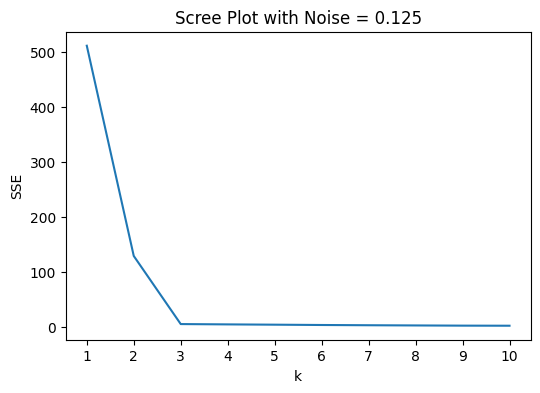

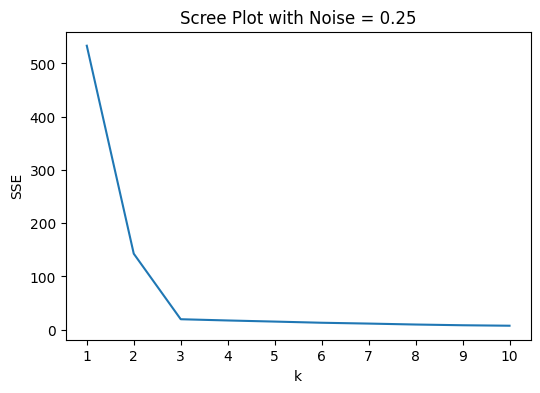

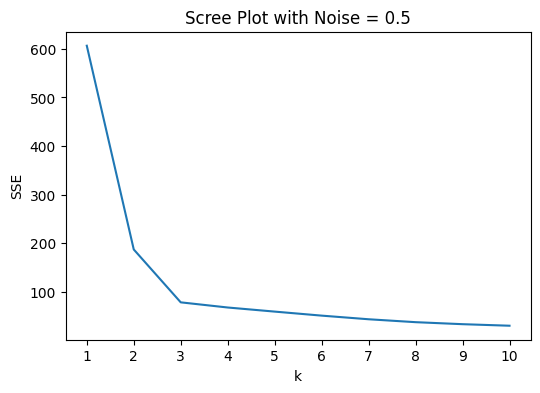

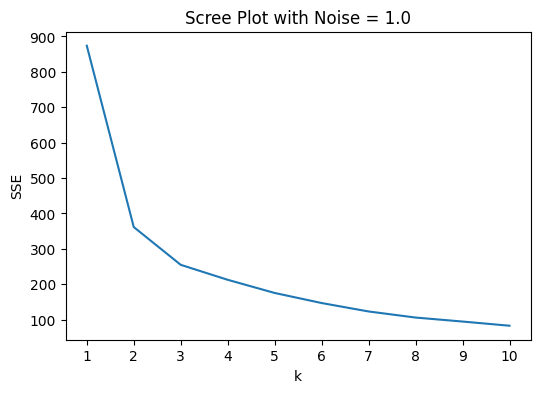

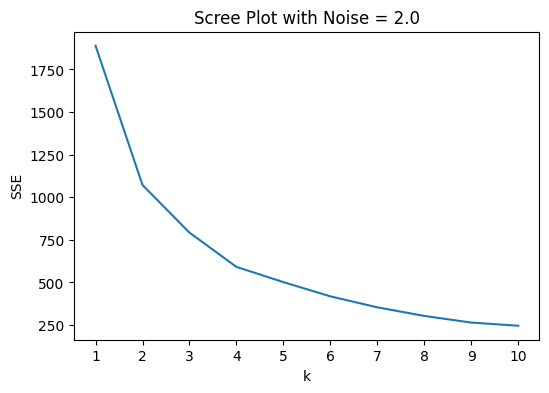

In [76]:
#Q.1.3

from sklearn.cluster import KMeans

ks = np.arange(1,11)

for i in range(len(datasets)):
  X = datasets[i][["x1","x2"]]

  SSE = [
      KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
      .fit(X).inertia_
      for k in ks
  ]

  plt.figure(figsize=(6, 4))
  sns.lineplot(x=ks, y=SSE)
  plt.title("Scree Plot with Noise = " + str(noise_levels[i]))
  plt.xlabel("k")
  plt.ylabel("SSE")
  plt.xticks(ks)
  plt.show()

As the noise increases, the scree plots show higher SSE values and the elbow becomes less clear. at lower noise levels, like 0.125 and 0.25, there is a sharp decrease in SSE until around k=3, where the curve starts to flatten. this makes it easier to identify 3 as the best choice for k. as noise increases to 0.5 and 1.0, the elbow becomes less noticeable because the sse decreases more gradually. at 2 the curve doesnt have a clear elbow making it harder to choose a k value. higher noise makes it harder to determine the appropriate number of clusters. sse values are also much higher in noisier datasets. i also noticed that the y-axis values are much higher for the noisier datasets because the points are more spread out from their cluster centers. this makes it important to compare the sse values across the plots instead of only looking at the shapes of the curves.

Q.1.4:

The intuition behind the elbow is that we want to find a value of k where adding more clusters no longer makes a significant improvement in SSE. when k is small, increasing the number of clusters can greatly reduce sse because the data points are being grouped closer to their centers. however, after a certain point, adding more clusters only makes a small difference. in this simulation, the lower noise datasets show a clear elbow around k=3, which makes sense because the data was originally created with three groups. after k=3, the sse decreases much more slowly because the main clusters have been identified already. with higher noise, the elbow becomes less obvious because the groups overlap more. this shows why the elbow method is useful for chooisng a k, but also why it becomes less reliable when the data is noisy.

In [77]:
#Q.2.1

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

#load data

df = pd.read_csv("./data/SIPRI Military Expenditure Database.csv")
df = df[df["Year"] == 2020].dropna().copy()
df = df.drop(columns=["index"])

print(df.shape)
print(df.dtypes)
df.head()

(148, 6)
Year                                int64
Country                            object
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object


,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
66,2020,Albania,187.433234,0.012583,0.037952,65.126211
100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
134,2020,Angola,993.594405,0.014442,0.074624,30.231680
168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731


after filtering the dataset to only include 2020 and dropping the rows with missing values, I was left with 148 countries. the only additional cleaning I needed was removing the extra index column, since it doesn't provide any useful information for clustering. i also kept the country names for identifying countries later, but only used the numerical spending variables in the clustering analysis.

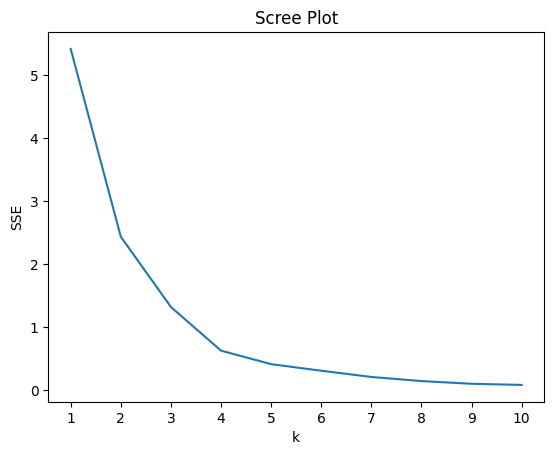

In [78]:
#Q.2.2

features = ["Spending (2020 USD)", "Spending per Capita"]

unscaled = df[features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges

ks = np.arange(1,11)

SSE = [
    KMeans(n_clusters = k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE).set(
    title="Scree Plot",
    xlabel="k",
    ylabel="SSE"
)
plt.xticks(ks)
plt.show()

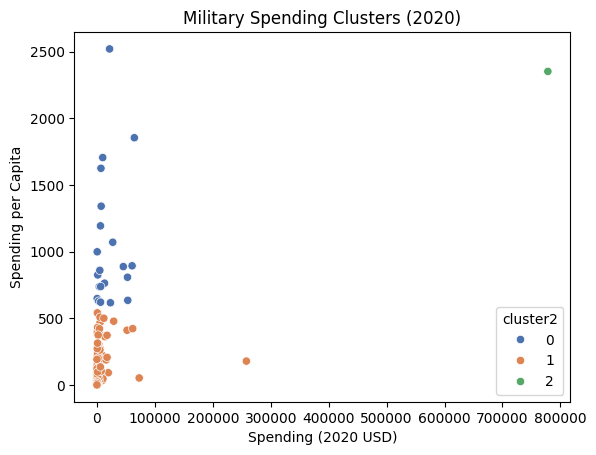

Spending (2020 USD)                                              \
                       count           mean           std            min   
cluster2                                                                   
0                       21.0   19975.991473  21749.736747     405.790494   
1                      126.0    5943.346303  24858.961064       8.622460   
2                        1.0  778397.200000           NaN  778397.200000   

                                                                      \
                    25%            50%            75%            max   
cluster2                                                               
0           4980.428135    7269.880030   27300.894701   64558.400000   
1            162.761743     580.758315    3225.333414  257973.429834   
2         778397.200000  778397.200000  778397.200000  778397.200000   

         Spending per Capita                                        \
                       count         mean         std          min   
cluster2                                                             
0                       21.0  1046.433509  501.631845   616.854430   
1                      126.0   122.034996  140.041183     0.580129   
2                        1.0  2351.631858         NaN  2351.631858   

                                                              
                  25%          50%          75%          max  
cluster2                                                      
0          737.690186   859.880548  1193.598730  2520.398541  
1           18.505805    58.809109   188.249364   541.154778  
2         2351.631858  2351.631858  2351.631858  2351.631858

In [79]:
model = KMeans(n_clusters=3, max_iter=300, n_init=10, random_state=0)
model.fit(X)
df["cluster2"] = model.labels_

sns.scatterplot(
    data=df,
    x="Spending (2020 USD)",
    y="Spending per Capita",
    hue="cluster2",
    palette="deep"
)
plt.title("Military Spending Clusters (2020)")
plt.show()
df.groupby("cluster2")[features].describe()

In [80]:
df[df["Country"] == "United States of America"][
  ["Country", "Spending (2020 USD)", "Spending per Capita", "cluster2"]
]

,Country,Spending (2020 USD),Spending per Capita,cluster2
5540,United States of America,778397.2,2351.631858,2


i chose k=3 based on the scree plot because the sse decreases more noticeably for the first few clusters and then starts to level off. looking at the scatterplot and describe table, i noticed that most countries are grouped into a cluster with relatively low military spending and spending per capita. there is also a smaller cluster with countries that have higher spending per capita. the united states stands out because it is the only country in cluster 2, with much higher total military spending than the other countries. i think this shows there are large differences in military spending across countries, especially when looking at total spending.

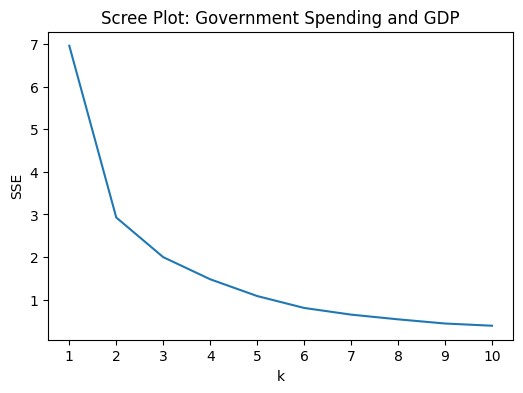

In [81]:
#Q.2.3

features3 = ["Percent of Government Spending", "Percent of GDP"]

X3 = df[features3]
X3 = (X3 - X3.min()) / (X3.max() - X3.min())

ks = np.arange(1,11)

SSE3 = [
    KMeans(n_clusters = k, max_iter=300, n_init=10, random_state=0)
    .fit(X3).inertia_
    for k in ks
]

plt.figure(figsize=(6,4))
sns.lineplot(x=ks, y=SSE3)
plt.title("Scree Plot: Government Spending and GDP")
plt.xlabel("k")
plt.ylabel("SSE")
plt.xticks(ks)
plt.show()

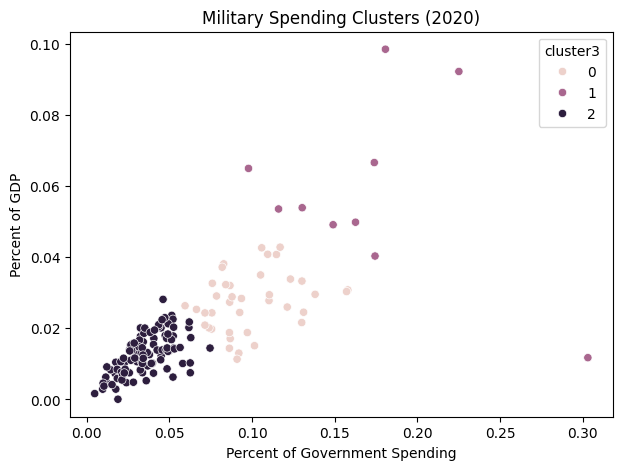

Percent of Government Spending                                \
                                  count      mean       std       min   
cluster3                                                                
0                                  39.0  0.098683  0.024125  0.059520   
1                                  10.0  0.171289  0.058725  0.097882   
2                                  99.0  0.035777  0.014549  0.004896   

                                                 Percent of GDP            \
               25%       50%       75%       max          count      mean   
cluster3                                                                    
0         0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1         0.135010  0.168248  0.179081  0.303027           10.0  0.058071   
2         0.025921  0.034261  0.047402  0.074624           99.0  0.012664   

                                                                      
               std       min       25%       50%       75%       max  
cluster3                                                              
0         0.008191  0.011317  0.021254  0.027781  0.032461  0.042810  
1         0.024867  0.011742  0.049297  0.053729  0.066190  0.098470  
2         0.005681  0.000054  0.008393  0.013191  0.016752  0.028132

In [82]:
model3 = KMeans(n_clusters=3, max_iter=300, n_init=10, random_state=0)
df["cluster3"] = model3.fit_predict(X3)

plt.figure(figsize=(7,5))
sns.scatterplot(
    data=df,
    x="Percent of Government Spending",
    y="Percent of GDP",
    hue="cluster3",
)
plt.title("Military Spending Clusters (2020)")
plt.show()
df.groupby("cluster3")[features3].describe()

In [83]:
df[df["Country"] == "United States of America"][
  ["Country", "Percent of Government Spending",
    "Percent of GDP", "cluster3"]]

,Country,Percent of Government Spending,Percent of GDP,cluster3
5540,United States of America,0.081976,0.037179,0


I chose k=3 to compare the results with Part 2, although the scree plot does not have a completely clear elbow. I noticed that most countries fall into the cluster with lower percentages of government spending and GDP going toward the military. there are also smaller groups of countries that spend higher percentages of their resources on the military. compared to part 2, the united states is no longer in a cluster by itself and is instead grouped with 38 other countries. i think this shows that even though the us has much higher total military spending, it is more similar to other countries when looking at military spending as a percentage of government spending and GDP.

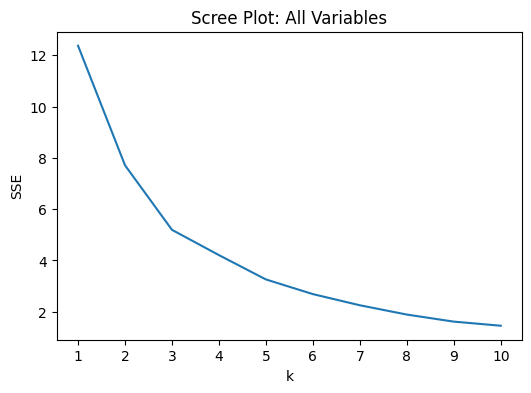

In [84]:
#Q.2.4

features4 = ["Spending (2020 USD)",
             "Spending per Capita",
             "Percent of Government Spending",
             "Percent of GDP"
]
X4 = df[features4]
X4 = (X4 - X4.min()) / (X4.max() - X4.min())

SSE4 = [
    KMeans(n_clusters = k, max_iter=300, n_init=10, random_state=0)
    .fit(X4).inertia_
    for k in ks
]

plt.figure(figsize=(6,4))
sns.lineplot(x=ks, y=SSE4)
plt.title("Scree Plot: All Variables")
plt.xlabel("k")
plt.ylabel("SSE")
plt.xticks(ks)
plt.show()

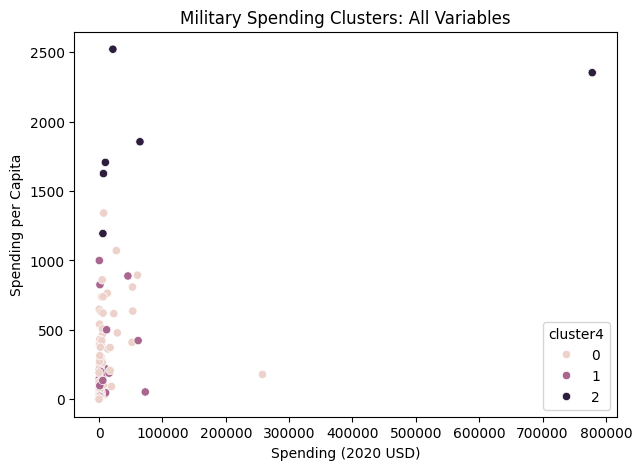

Spending (2020 USD)                                             \
                       count           mean            std          min   
cluster4                                                                  
0                      111.0    7086.472777   26479.379918     8.622460   
1                       31.0    8786.086602   17901.909108   162.373364   
2                        6.0  147964.582042  309635.189564  6095.708713   

                                                                  \
                  25%           50%           75%            max   
cluster4                                                           
0          130.010211    567.650747   3910.107493  257973.429834   
1          467.787851   1404.787234   7739.166193   72937.064048   
2         7700.424616  15897.570598  53872.942442  778397.200000   

         Spending per Capita               ... Percent of Government Spending  \
                       count         mean  ...                            75%   
cluster4                                   ...                                  
0                      111.0   196.926833  ...                       0.050505   
1                       31.0   212.689100  ...                       0.134663   
2                        6.0  1875.150751  ...                       0.164503   

                   Percent of GDP                                          \
               max          count      mean       std       min       25%   
cluster4                                                                    
0         0.092044          111.0  0.013419  0.005996  0.000054  0.008873   
1         0.303027           31.0  0.033492  0.011449  0.011742  0.027560   
2         0.225050            6.0  0.062634  0.028275  0.029429  0.041272   

                                        
               50%       75%       max  
cluster4                                
0         0.013589  0.017769  0.028132  
1         0.032024  0.040531  0.066600  
2         0.059257  0.085398  0.098470  

[3 rows x 32 columns]

In [85]:
model4 = KMeans(n_clusters=3, max_iter=300, n_init=10, random_state=0)
model4.fit(X4)
df["cluster4"] = model4.labels_

plt.figure(figsize=(7,5))
sns.scatterplot(
    data=df,
    x="Spending (2020 USD)",
    y="Spending per Capita",
    hue="cluster4",
)
plt.title("Military Spending Clusters: All Variables")
plt.show()
df.groupby("cluster4")[features4].describe()

In [86]:
df[df["Country"] == "United States of America"][
    ["Country", "cluster2", "cluster3", "cluster4"]
]

,Country,cluster2,cluster3,cluster4
5540,United States of America,2,0,2


In [87]:
df[df["cluster4"] == 2][
    ["Country", "Spending (2020 USD)", "Spending per Capita",
     "Percent of Government Spending", "Percent of GDP"]
]

,Country,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
2582,Israel,21816.569767,2520.398541,0.116052,0.053553
2922,Kuwait,6941.042345,1625.156250,0.097882,0.064961
4044,Oman,6095.708713,1193.598730,0.180654,0.098470
4486,Saudi Arabia,64558.400000,1854.380422,0.225050,0.092211
4656,Singapore,9978.571429,1705.738706,0.110489,0.029429
5540,United States of America,778397.200000,2351.631858,0.081976,0.037179


i used all four variables and chose k=3 to compare the results with the previous two parts. i noticed that most countries are grouped into one large cluster, while the smaller clusters represent countries with different military spending patterns. compared to part 2, the united states is no longer in a cluster by itself and is now grouped with five other countries, including israel and saudi arabia. compared to part 3, the clusters also changed because total spending and spending per capita were included along with the percentage variables. i think used all four variables gives a more complete picture of military spending because it considers both how much countries spend and how much of their resources go toward the military.

Q.2.5

i think the k-means clustering algorithm was useful for identifying patterns in military spending across countries. one of the biggest things i noticed was how much the clusters changed depending on which variables were used. in part 2, the united states was in its own cluster because of its significantly higher total military spending, however, when looking at spending as a percentage of government spending and GDP, the US was grouped with other countries. using all four variables also showed similarities between countries that were not as obvious when looking at only two variables. overall i think k-means was helpful for understanding different military spending patterns, but the results also showed how important the choice of variables is when clustering data.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** a736093
- **AI tool and model used:** ChatGPT GPT-5.6 Sol

### *Prompts used

1. Review my Phase 1 solution and tell me what I should improve for Phase 2. Focus on any errors, unclear explanations, unnecessary code, or parts that could be more complete, but keep my original approach and work as much as possible.
2. Go through each section of my Phase 1 solution and tell me exactly what I should change or clarify. Provide a concise numbered list. For anything that needs improvement, explain why and suggest a specific revision.

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Q1.1 — Keep the data-generation code unchanged. The code correctly generates all five datasets with the required noise levels. No revisions are necessary because this section meets the rubric requirements.
2. Q1.2 — Keep the scatterplots but improve the explanation of noise. The code correctly produces five scatterplots colored by group. The explanation already identifies how increasing noise makes clusters more spread out and harder to distinguish. Improve it by explicitly connecting the increasing overlap between groups to the difficulty of identifying distinct clusters. Correct minor grammatical and capitalization errors.
3. Q1.3 — Clarify how noise affects the scree plots and selecting \(k\). The code correctly generates scree plots for all five datasets using \(k=1\) through \(10\). Keep the existing code, but clarify that the elbow is easier to identify around \(k=3\) for lower-noise datasets and becomes less distinct as noise increases. Revise the final sentence to explain that comparing the shape of the SSE curves is more useful for selecting \(k\) than comparing their absolute SSE values across datasets.
4. Q1.4 — Make the elbow interpretation more precise. The existing explanation correctly identifies the elbow as the point where additional clusters produce smaller improvements in SSE. Clarify that SSE continues to decrease as \(k\) increases, but the improvement becomes less significant after the elbow. Keep the connection to the three original groups because it demonstrates why \(k=3\) makes sense in this simulation.
5. Q2.1 — Clarify why no additional numerical cleaning is necessary. The code correctly filters the dataset to 2020, removes missing values, and drops the unnecessary index column. Add a sentence explaining that the four spending variables are already numeric and can be used for clustering without additional type conversion. Keep the original data-cleaning approach.
6. Q2.2 — Strengthen the explanation of the scree plot and cluster patterns. The code correctly applies max-min normalization, produces the scree plot and cluster-colored scatterplot, and calculates descriptive statistics. Improve the explanation by making the reasoning for choosing \(k=3\) more specific. Reference the cluster sizes of 126, 21, and 1 countries and explain how the descriptive statistics support the observation that the United States forms its own cluster due to its unusually high total military spending.
7. Q2.3 — Make the comparison with Q2.2 more specific. The code correctly normalizes both percentage variables and generates the required plots and descriptive statistics. Keep \(k=3\) for consistency, but acknowledge that the elbow is not completely clear. Strengthen the comparison by explaining that absolute spending measures the total amount spent, while percentage variables show how much of a country's resources are allocated to the military. Include that the United States is now grouped with 38 other countries rather than being isolated.
8. Q2.4 — Expand the comparison of all four variables. The code correctly normalizes and clusters all four numerical variables. Keep the original approach, but explain more specifically how including both absolute and percentage-based spending changes cluster membership. Identify the six countries grouped together in the United States' cluster and clarify that they share similar patterns across the combined normalized variables rather than necessarily having similar total military expenditures.
9. Q2.5 — Strengthen the conclusion about the usefulness of K-means. The current conclusion correctly explains that clustering results change depending on the variables selected. Add that K-means was useful for distinguishing between absolute military spending and military spending relative to national resources. Acknowledge that the interpretation is limited by the choice of variables, normalization, and number of clusters.
10. Overall — Improve readability while preserving the original solution. Correct minor spelling, grammar, and capitalization errors throughout the written explanations. Keep the original code structure, normalization methods, plots, and K-means implementation because they already address the technical requirements of the rubric. Avoid introducing unnecessary code that does not directly improve accuracy or interpretation.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | The original code already generates the five required noise datasets, so no changes are necessary. I can verify this by checking that all five datasets are created with the correct noise levels. |
| 2 | Accept | The scatterplots already meet the rubric requirements, but the explanation can be more specific about how increasing noise makes the clusters overlap and become harder to distinguish. I can verify this by comparing the five scatterplots. |
| 3 | Accept | Clarifying how noise affects the elbow will make my explanation more complete. I can compare the scree plots to check whether the elbow becomes less distinct as noise increases and how this affects selecting. |
| 4 | Accept | The original explanation is correct, but clarifying that SSE continues decreasing after the elbow will make it more accurate. I can verify this by looking at the SSE values as \(k\) increases. |
| 5 | Accept | Explaining why no additional cleaning is necessary will better address the rubric. I can verify this by checking the variable data types and confirming that missing values were removed. |
| 6 | Accept | Including the cluster sizes and explaining why the United States forms its own cluster will strengthen my interpretation. I can verify this using the descriptive statistics and scatterplot. |
| 7 | Accept | A more specific comparison will help explain why the clustering results change when using percentage variables instead of absolute spending. I can verify this by comparing the cluster assignments and descriptive statistics from both analyses. |
| 8 | Accept | Explaining how combining all four variables changes the clusters will make the comparison more complete. I can verify the countries grouped with the United States by checking the cluster assignments in the dataset. |
| 9 | Accept | Adding the limitations of K-means will make my conclusion more balanced and address the usefulness of the algorithm more completely. I can support this by comparing how the results change across the three analyses. |
| 10 | Modify | I agree with correcting grammatical errors and improving readability, but I do not think changing the existing code structure is necessary because it already addresses the rubric. I will keep the original code and focus on making the explanations clearer. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [88]:
# Your Phase 2 solution to the problem goes here.

In [89]:
#Q.1.1

import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

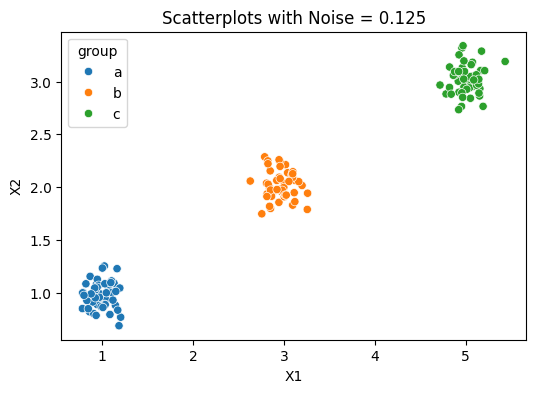

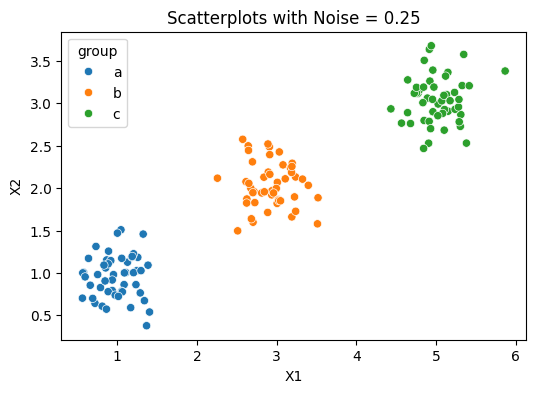

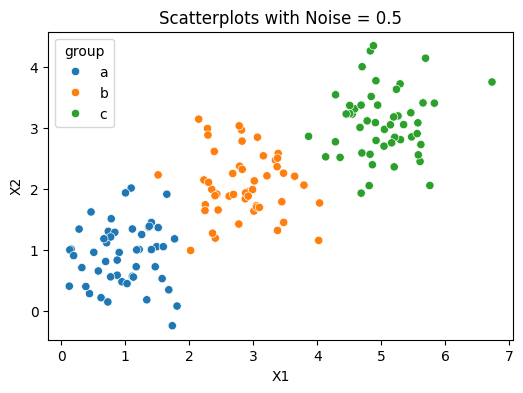

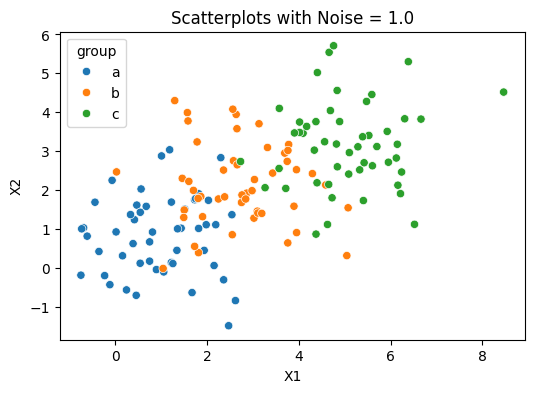

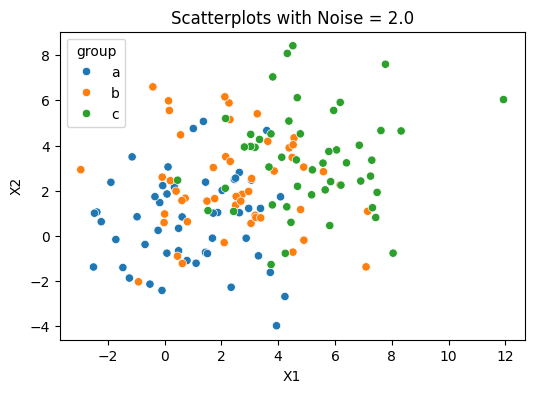

In [90]:
#Q.1.2

import matplotlib.pyplot as plt
import seaborn as sns

datasets = [df0_125, df0_25, df0_5, df1_0, df2_0]
noise_levels = [0.125, 0.25, 0.5, 1.0, 2.0]

for i in range(len(datasets)):
  plt.figure(figsize=(6,4))
  sns.scatterplot(data=datasets[i], x="x1", y="x2", hue="group")
  plt.title("Scatterplots with Noise = " + str(noise_levels[i]))
  plt.xlabel("X1")
  plt.ylabel("X2")
  plt.show()

As the noise increases from 0.125 to 2.0, the clusters spread out more. At lower noise levels, the three groups are closely concentrated around their centers and are easier to identify. As the noise increases to 0.5 and 1.0, the points become more spread out and the groups start to overlap. At noise = 2.0, there is much more overlap, making it difficult to visually separate the three groups. Increasing noise makes the clusters less distinct, even though the data was originally generated from three groups.

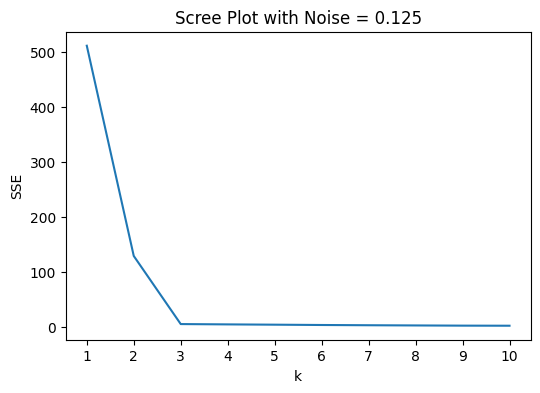

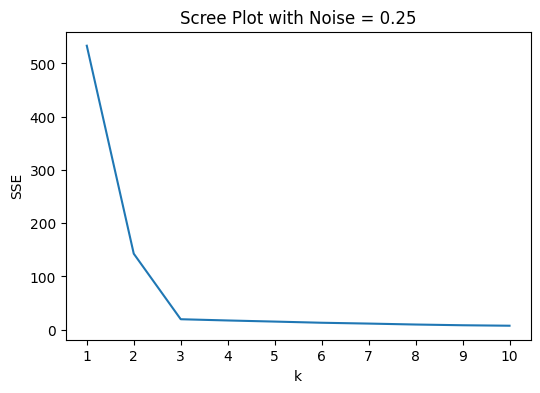

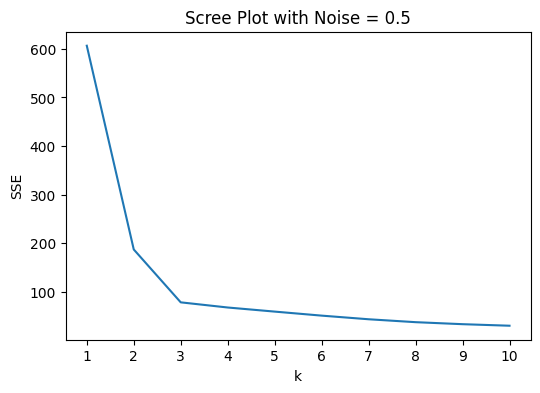

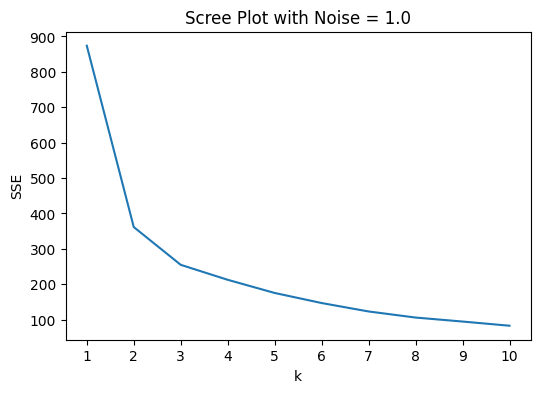

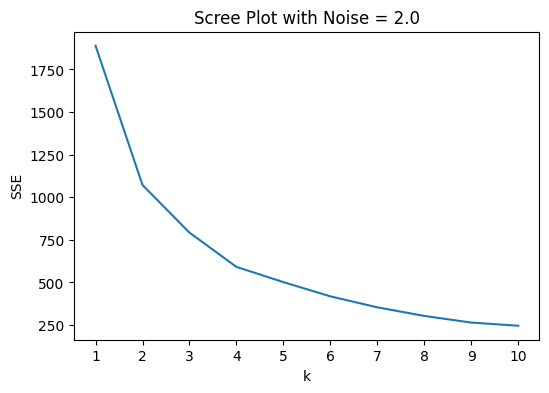

In [91]:
#Q.1.3

from sklearn.cluster import KMeans

ks = np.arange(1,11)

for i in range(len(datasets)):
  X = datasets[i][["x1","x2"]]

  SSE = [
      KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
      .fit(X).inertia_
      for k in ks
  ]

  plt.figure(figsize=(6, 4))
  sns.lineplot(x=ks, y=SSE)
  plt.title("Scree Plot with Noise = " + str(noise_levels[i]))
  plt.xlabel("k")
  plt.ylabel("SSE")
  plt.xticks(ks)
  plt.show()

As the noise increases, the scree plots generally have higher SSE values and the elbow becomes less clear. At lower noise levels, especially 0.125 and 0.25, SSE drops sharply until around k=3 and then decreases more slowly, making k=3 easier to identify. At noise levels of 0.5 and 1.0, the elbow is less noticeable, and at 2.0 it is difficult to choose a single k from the curve. Higher noise spreads points farther from their assigned cluster centers, increasing SSE. Because the scales differ across datasets, I focused on the shape of each curve and where the decrease in SSE starts to slow down, rather than comparing the raw SSE values between plots to choose k.

Q1.4: The intuition behind the elbow is to find a value of k where adding more clusters no longer makes as much improvement in SSE. When k is small, increasing the number of clusters can greatly reduce SSE because points can be assigned to closer centers. After the elbow, SSE still decreases as k increases, but each additional cluster gives a smaller improvement. In this simulation, the lower-noise datasets show an elbow around k=3, which makes sense because the data was originally created with three groups. With higher noise, the groups overlap more, so the elbow becomes less obvious. This shows why the elbow method is useful for choosing k, but also why the choice is less certain with noisier data.

In [92]:
#Q.2.1

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

#load data

df = pd.read_csv("./data/SIPRI Military Expenditure Database.csv")
df = df[df["Year"] == 2020].dropna().copy()
df = df.drop(columns=["index"])

print(df.shape)
print(df.dtypes)
df.head()

(148, 6)
Year                                int64
Country                            object
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object


,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
66,2020,Albania,187.433234,0.012583,0.037952,65.126211
100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
134,2020,Angola,993.594405,0.014442,0.074624,30.231680
168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731


After filtering the dataset to 2020 and dropping rows with missing values, I was left with 148 countries. I removed the extra index column because it does not provide useful information for clustering. The four spending variables are already numeric, so they do not require additional type conversion. I kept the country names to identify countries later, but used only the selected numeric spending variables in each clustering analysis.

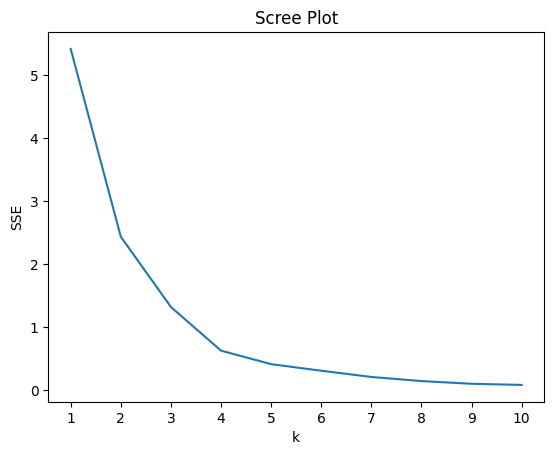

In [93]:
#Q.2.2

features = ["Spending (2020 USD)", "Spending per Capita"]

unscaled = df[features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges

ks = np.arange(1,11)

SSE = [
    KMeans(n_clusters = k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]

sns.lineplot(x=ks, y=SSE).set(
    title="Scree Plot",
    xlabel="k",
    ylabel="SSE"
)
plt.xticks(ks)
plt.show()

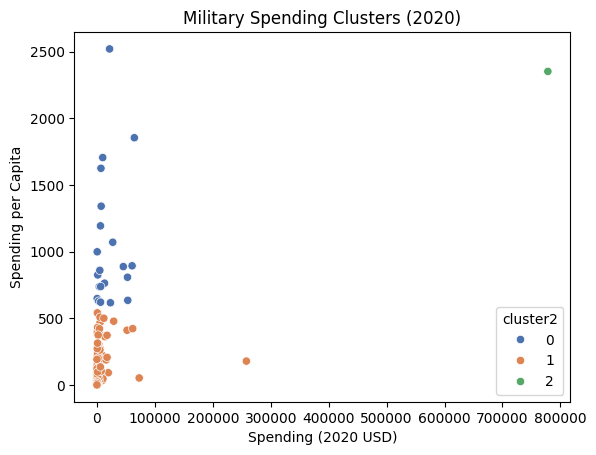

Spending (2020 USD)                                              \
                       count           mean           std            min   
cluster2                                                                   
0                       21.0   19975.991473  21749.736747     405.790494   
1                      126.0    5943.346303  24858.961064       8.622460   
2                        1.0  778397.200000           NaN  778397.200000   

                                                                      \
                    25%            50%            75%            max   
cluster2                                                               
0           4980.428135    7269.880030   27300.894701   64558.400000   
1            162.761743     580.758315    3225.333414  257973.429834   
2         778397.200000  778397.200000  778397.200000  778397.200000   

         Spending per Capita                                        \
                       count         mean         std          min   
cluster2                                                             
0                       21.0  1046.433509  501.631845   616.854430   
1                      126.0   122.034996  140.041183     0.580129   
2                        1.0  2351.631858         NaN  2351.631858   

                                                              
                  25%          50%          75%          max  
cluster2                                                      
0          737.690186   859.880548  1193.598730  2520.398541  
1           18.505805    58.809109   188.249364   541.154778  
2         2351.631858  2351.631858  2351.631858  2351.631858

In [94]:
model = KMeans(n_clusters=3, max_iter=300, n_init=10, random_state=0)
model.fit(X)
df["cluster2"] = model.labels_

sns.scatterplot(
    data=df,
    x="Spending (2020 USD)",
    y="Spending per Capita",
    hue="cluster2",
    palette="deep"
)
plt.title("Military Spending Clusters (2020)")
plt.show()
df.groupby("cluster2")[features].describe()

In [95]:
df[df["Country"] == "United States of America"][
  ["Country", "Spending (2020 USD)", "Spending per Capita", "cluster2"]
]

,Country,Spending (2020 USD),Spending per Capita,cluster2
5540,United States of America,778397.2,2351.631858,2


I chose k=3 because the scree plot shows larger reductions in SSE for the first few clusters before the curve begins to level off, although the elbow is not perfectly sharp. Looking at the scatterplot and describe table, I noticed that most countries are in cluster 1 (126 countries), with generally lower spending per capita. Cluster 0 contains 21 countries with higher spending per capita on average. The United States is the only country in cluster 2 (1 country) and has much higher total military spending than the other countries. The describe table also shows that the standard deviation for the one-country cluster is undefined because it only has one observation. These results show how different absolute military spending can be across countries.

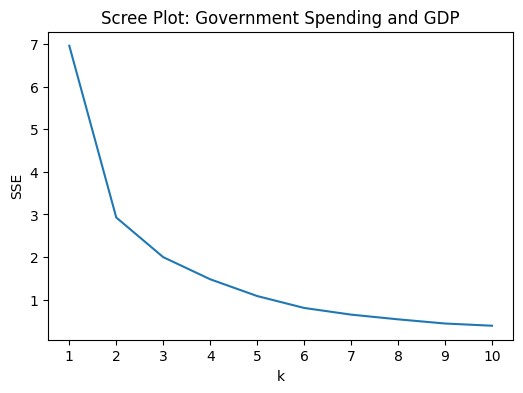

In [96]:
#Q.2.3

features3 = ["Percent of Government Spending", "Percent of GDP"]

X3 = df[features3]
X3 = (X3 - X3.min()) / (X3.max() - X3.min())

ks = np.arange(1,11)

SSE3 = [
    KMeans(n_clusters = k, max_iter=300, n_init=10, random_state=0)
    .fit(X3).inertia_
    for k in ks
]

plt.figure(figsize=(6,4))
sns.lineplot(x=ks, y=SSE3)
plt.title("Scree Plot: Government Spending and GDP")
plt.xlabel("k")
plt.ylabel("SSE")
plt.xticks(ks)
plt.show()

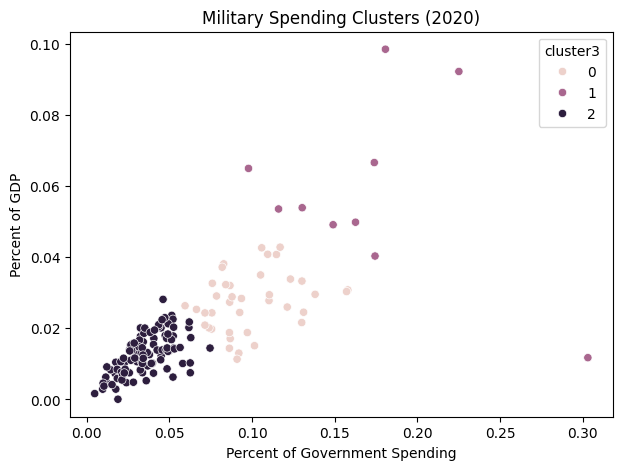

Percent of Government Spending                                \
                                  count      mean       std       min   
cluster3                                                                
0                                  39.0  0.098683  0.024125  0.059520   
1                                  10.0  0.171289  0.058725  0.097882   
2                                  99.0  0.035777  0.014549  0.004896   

                                                 Percent of GDP            \
               25%       50%       75%       max          count      mean   
cluster3                                                                    
0         0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1         0.135010  0.168248  0.179081  0.303027           10.0  0.058071   
2         0.025921  0.034261  0.047402  0.074624           99.0  0.012664   

                                                                      
               std       min       25%       50%       75%       max  
cluster3                                                              
0         0.008191  0.011317  0.021254  0.027781  0.032461  0.042810  
1         0.024867  0.011742  0.049297  0.053729  0.066190  0.098470  
2         0.005681  0.000054  0.008393  0.013191  0.016752  0.028132

In [97]:
model3 = KMeans(n_clusters=3, max_iter=300, n_init=10, random_state=0)
df["cluster3"] = model3.fit_predict(X3)

plt.figure(figsize=(7,5))
sns.scatterplot(
    data=df,
    x="Percent of Government Spending",
    y="Percent of GDP",
    hue="cluster3",
)
plt.title("Military Spending Clusters (2020)")
plt.show()
df.groupby("cluster3")[features3].describe()

In [98]:
df[df["Country"] == "United States of America"][
  ["Country", "Percent of Government Spending",
    "Percent of GDP", "cluster3"]]

,Country,Percent of Government Spending,Percent of GDP,cluster3
5540,United States of America,0.081976,0.037179,0


I chose k=3 to compare the results with Part 2, although the scree plot does not have a completely clear elbow. The describe table shows 99 countries in cluster 2, 39 in cluster 0, and 10 in cluster 1. Cluster 2 has the lowest average percentages of government spending and GDP going toward the military, while the smaller clusters generally have higher percentages. Compared to Part 2, the United States is no longer in a cluster by itself: it is in cluster 0 with 38 other countries. I think this shows that, although the U.S. has much higher total military spending, it is more similar to other countries when military spending is measured as a share of government spending and GDP. These percentage variables describe the relative priority of military spending rather than the total amount spent.

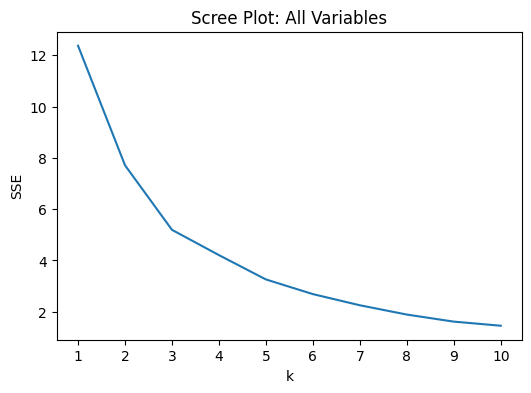

In [99]:
#Q.2.4

features4 = ["Spending (2020 USD)",
             "Spending per Capita",
             "Percent of Government Spending",
             "Percent of GDP"
]
X4 = df[features4]
X4 = (X4 - X4.min()) / (X4.max() - X4.min())

SSE4 = [
    KMeans(n_clusters = k, max_iter=300, n_init=10, random_state=0)
    .fit(X4).inertia_
    for k in ks
]

plt.figure(figsize=(6,4))
sns.lineplot(x=ks, y=SSE4)
plt.title("Scree Plot: All Variables")
plt.xlabel("k")
plt.ylabel("SSE")
plt.xticks(ks)
plt.show()

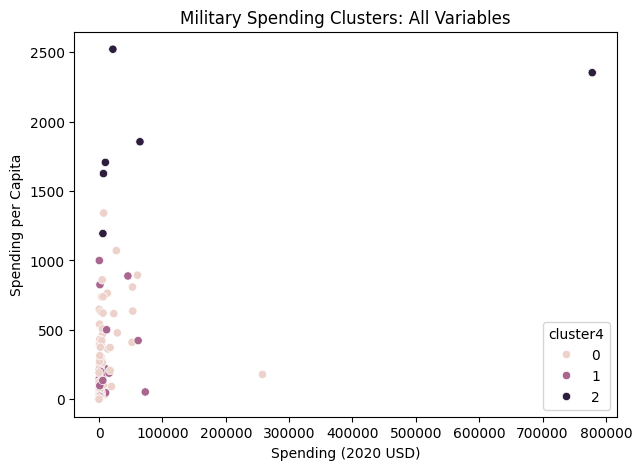

Spending (2020 USD)                                             \
                       count           mean            std          min   
cluster4                                                                  
0                      111.0    7086.472777   26479.379918     8.622460   
1                       31.0    8786.086602   17901.909108   162.373364   
2                        6.0  147964.582042  309635.189564  6095.708713   

                                                                  \
                  25%           50%           75%            max   
cluster4                                                           
0          130.010211    567.650747   3910.107493  257973.429834   
1          467.787851   1404.787234   7739.166193   72937.064048   
2         7700.424616  15897.570598  53872.942442  778397.200000   

         Spending per Capita               ... Percent of Government Spending  \
                       count         mean  ...                            75%   
cluster4                                   ...                                  
0                      111.0   196.926833  ...                       0.050505   
1                       31.0   212.689100  ...                       0.134663   
2                        6.0  1875.150751  ...                       0.164503   

                   Percent of GDP                                          \
               max          count      mean       std       min       25%   
cluster4                                                                    
0         0.092044          111.0  0.013419  0.005996  0.000054  0.008873   
1         0.303027           31.0  0.033492  0.011449  0.011742  0.027560   
2         0.225050            6.0  0.062634  0.028275  0.029429  0.041272   

                                        
               50%       75%       max  
cluster4                                
0         0.013589  0.017769  0.028132  
1         0.032024  0.040531  0.066600  
2         0.059257  0.085398  0.098470  

[3 rows x 32 columns]

In [100]:
model4 = KMeans(n_clusters=3, max_iter=300, n_init=10, random_state=0)
model4.fit(X4)
df["cluster4"] = model4.labels_

plt.figure(figsize=(7,5))
sns.scatterplot(
    data=df,
    x="Spending (2020 USD)",
    y="Spending per Capita",
    hue="cluster4",
)
plt.title("Military Spending Clusters: All Variables")
plt.show()
df.groupby("cluster4")[features4].describe()

In [101]:
df[df["Country"] == "United States of America"][
    ["Country", "cluster2", "cluster3", "cluster4"]
]

,Country,cluster2,cluster3,cluster4
5540,United States of America,2,0,2


In [102]:
df[df["cluster4"] == 2][
    ["Country", "Spending (2020 USD)", "Spending per Capita",
     "Percent of Government Spending", "Percent of GDP"]
]

,Country,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
2582,Israel,21816.569767,2520.398541,0.116052,0.053553
2922,Kuwait,6941.042345,1625.156250,0.097882,0.064961
4044,Oman,6095.708713,1193.598730,0.180654,0.098470
4486,Saudi Arabia,64558.400000,1854.380422,0.225050,0.092211
4656,Singapore,9978.571429,1705.738706,0.110489,0.029429
5540,United States of America,778397.200000,2351.631858,0.081976,0.037179


I used all four variables and chose k=3 to compare the results with the previous two parts. The describe table shows 111 countries in cluster 0, 31 in cluster 1, and 6 in cluster 2. Compared to Part 2, the United States is no longer in a cluster by itself. Instead, it is grouped with Israel, Kuwait, Oman, Saudi Arabia, and Singapore. Compared to Part 3, the clusters change again because total spending and spending per capita are included alongside the two percentage variables. These six countries show similar patterns when all four normalized variables are considered together, but they do not necessarily spend similar total amounts. I think using all four variables gives a more complete picture because it considers both how much countries spend and how much of their resources go toward the military.

Q2.5: I think K-means clustering was useful for identifying patterns in military spending across countries. One of the biggest things I noticed was how much the clusters changed depending on which variables were used. In Part 2, the United States was in its own cluster because of its much higher total military spending. However, when looking at spending as a percentage of government spending and GDP in Part 3, the U.S. was grouped with other countries. Using all four variables in Part 4 also showed similarities that were not as obvious when looking at only two variables. Overall, K-means helped me distinguish patterns in absolute military spending from spending relative to national resources. However, the results depend on which variables are included, how they are normalized, and the choice of k, so the clusters are not the only possible way to group the countries.

### *Reflection on AI assistance
In your own words without generative AI.

Throughout Phase 2, the main improvements I focused on were making my explanations more specific and connecting my interpretations more directly to the results. For Question 1, I clarified how increasing noise affects the separation of clusters and makes the elbow in the scree plots harder to identify. For Question 2, I improved my comparisons between the different spending variables by including cluster sizes, descriptive statistics, and observations about how the United States was grouped.

One limitation I noticed with the AI suggestions was that some changes were not really necessary. My original code already addressed most of the rubric requirements, so changing the structure or adding more code would not necessarily make my solution better. I also recognized that AI interpretations should not automatically be assumed correct without checking the results.

To verify the revisions, I compared the scatterplots and scree plots, reviewed the descriptive statistics, and confirmed that the cluster sizes and country memberships match the code outputs. One remaining concern is that choosing the best value of k is not always straightforward, especially when the elbow is less distinct. Overall, the revisions helped make the analysis more complete while keeping my original approach.